# Detect and identify fossil specimens

This demonstration runs saved RF-DETR, Swin and DINO models on verified validation examples. It starts with a prepared RGB region and shows detection, specimen cropping and classification. Whole-slide focal selection and tiling are covered in the preprocessing workflow.

The saved outputs below show a completed run on validation examples. Display images are compressed previews; models use the original images.

**To rerun:** follow [installation and artifact retrieval](README.md). Copy `config/demo.example.json` to `config/local.demo.json`, set your paths, and select the `Smithsonian review` kernel. Cells execute from top to bottom. Each run uses a new output directory. Missing or mismatched artifacts cause an explicit error.

In [1]:
import os
from pathlib import Path
from uuid import uuid4
from IPython.display import display, HTML
from PIL import Image
from smithsonian.configuration.paths import repository_root
from smithsonian.configuration.options import save_effective_config
from smithsonian.inference.demo import (
    prepare_demo, classify_example, detect_example,
    annotate_predictions, prediction_table, preview_image,
)

# Verify the demo inputs and create a new folder for this run.
config_path = Path(os.environ.get("SMITHSONIAN_DEMO_CONFIG", repository_root() / "config/local.demo.json"))
config, sample = prepare_demo(config_path)
output = Path(config["output"]) / uuid4().hex[:12]
output.mkdir(parents=True, exist_ok=False)
save_effective_config(config, output / "effective_config.json")
print("Verified validation images and model checkpoints.")
print("Run folder:", output.name)

Verified validation images and model checkpoints.
Run folder: 22e240e139d2


## 1. A real specimen and its expert reference
The reference is the expert annotation; model predictions may differ.

Reference: Taxodium sp.
Source record: C_418114_W_Nassichuk_L_2025_01_14_16_15_48_Alaska::ndpviewstate:108


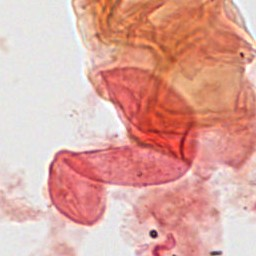

In [2]:
print("Reference:", sample["category"])
print("Source record:", sample["record_id"])
with Image.open(config["specimen"]) as image:
    display(preview_image(image))

## 2. Saved Swin and DINO classifiers
Swin and DINO classify the same specimen crop. Each score is the model probability assigned to its predicted category. Compare the prediction with the expert reference.

In [3]:
# Run both saved classifiers on the same specimen.
specimen_results = {
    model: classify_example(config, model, output / f"specimen_{model}.json")
    for model in ("swin", "dino")
}
for model, result in specimen_results.items():
    row = result["predictions"][0]
    print(f"{model}: {row['category']} ({row['score']:.1%})")

{"outputs": 1, "categories": ["Taxodium sp."]}


<DINO_SOURCE>/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
<DINO_SOURCE>/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
<DINO_SOURCE>/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


{"outputs": 1, "categories": ["Platycarya platycarioides"]}
swin: Taxodium sp. (76.7%)
dino: Platycarya platycarioides (69.4%)


## 3. Detect specimens in a region
RF-DETR returns boxes in this image’s pixel coordinates. The same boxes will be used for both classifiers.

<PYTHON_ENV>/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[2026-11-04 16:23:58] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-11-04 16:23:58] [WARNING] rf-detr - Using patch size 20 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-11-04 16:24:06] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. You can optimize the model for inference by calling model.optimize_for_inference().


[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


{"detections": 1}
Detected specimens: 1


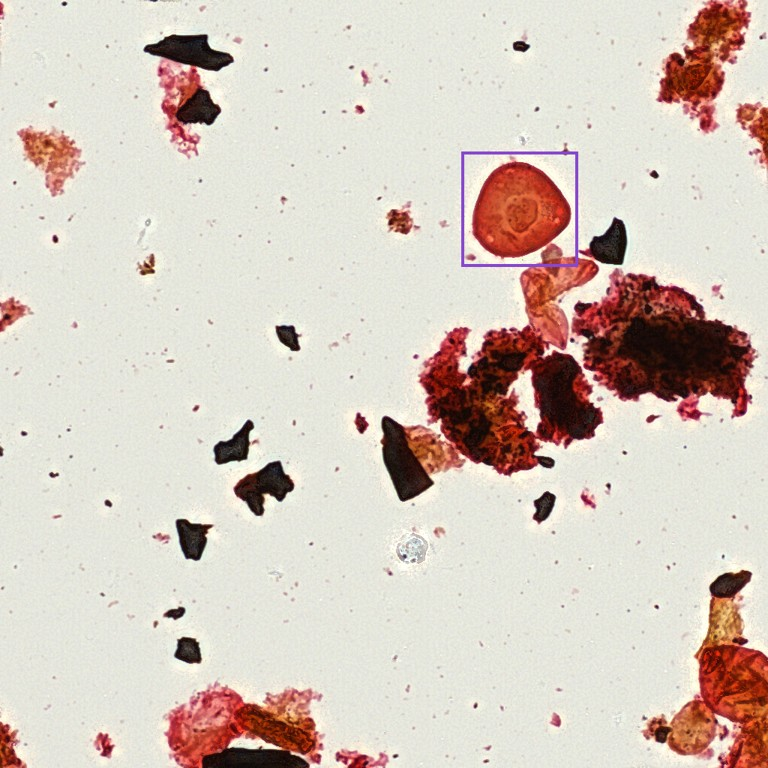

In [4]:
detections = detect_example(config, output / "detection")
print("Detected specimens:", len(detections["predictions"]))
with Image.open(config["image"]) as image:
    region_preview = image.convert("RGB")

# Display the detector boxes before passing them to the classifiers.
from PIL import ImageDraw
draw = ImageDraw.Draw(region_preview)
for detection in detections["predictions"]:
    draw.rectangle(detection["box"], outline="#8747cf", width=4)
display(preview_image(region_preview))

## 4. Crop and identify each detection
The package adds the fixed 10% context margin, pads in white and resizes to 224×224 pixels. Swin and DINO are alternative classifiers.

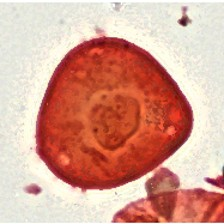

In [5]:
from smithsonian.preprocessing.crops import crop_input

# Display the classifier crops using the same padding and resize rules.
with Image.open(config["image"]) as source:
    region = source.convert("RGB")
    for detection in detections["predictions"][:6]:
        display(preview_image(crop_input(region, detection["box"])))


{"outputs": 1, "categories": ["Caryapollenites"]}


{"outputs": 1, "categories": ["Caryapollenites"]}
SWIN


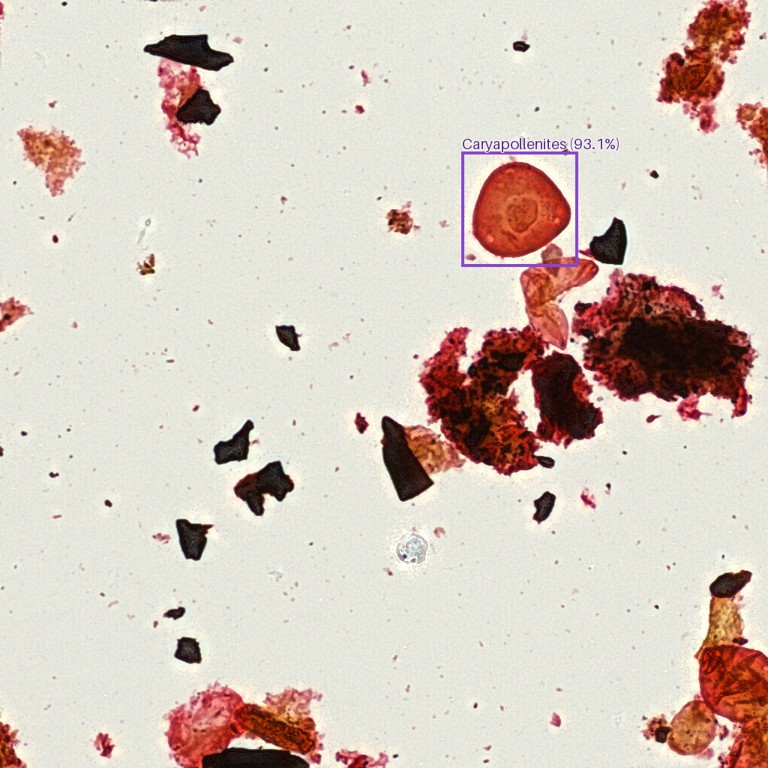

DINO


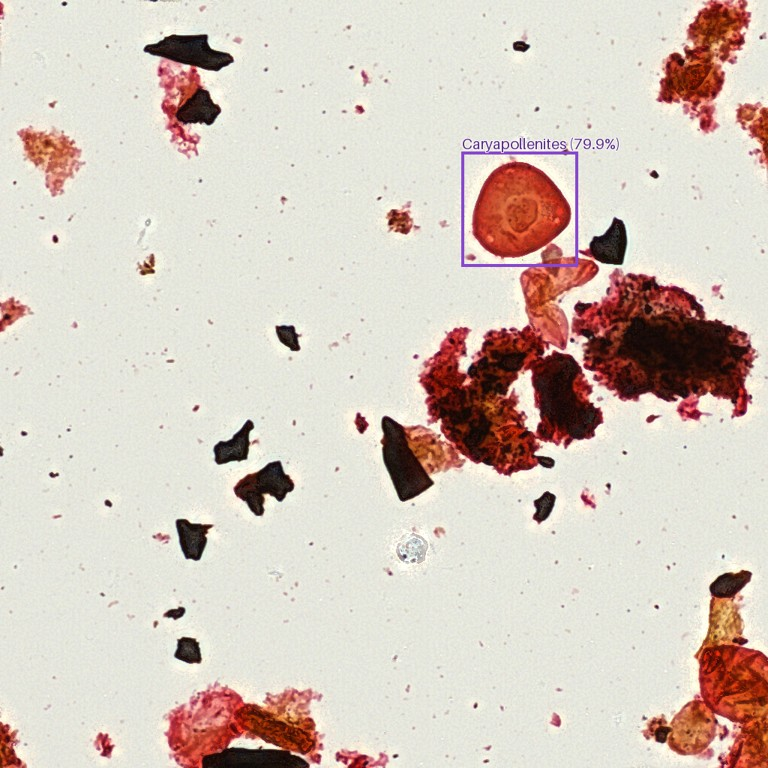

In [6]:
# Keep detection boxes fixed while comparing the two classifiers.
combined_results = {
    model: classify_example(
        config, model, output / f"combined_{model}.json",
        image=config["image"], boxes=output / "detection/boxes.json",
    )
    for model in ("swin", "dino")
}
for model, result in combined_results.items():
    print(model.upper())
    display(preview_image(annotate_predictions(config["image"], result)))

## 5. Output table
The table lists predicted categories and scores for each detection in this region. JSON outputs retain all category probabilities and input hashes.

In [7]:
from html import escape
import csv

# Save the predictions and show the same rows as a readable table.
rows = prediction_table(combined_results)
columns = ["model", "specimen", "category", "score", "box"]
with (output / "predictions.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=columns)
    writer.writeheader()
    writer.writerows(rows)
header = "".join(f"<th>{escape(key)}</th>" for key in columns)
body = "".join("<tr>" + "".join(f"<td>{escape(str(row[key]))}</td>" for key in columns) + "</tr>" for row in rows)
display(HTML(f"<table><tr>{header}</tr>{body}</table>"))
print("Saved predictions.csv in run", output.name)

model,specimen,category,score,box
swin,1,Caryapollenites,0.9312217831611633,"[615.8304443359375, 202.77011108398438, 770.7193603515625, 355.1460266113281]"
dino,1,Caryapollenites,0.7993979454040527,"[615.8304443359375, 202.77011108398438, 770.7193603515625, 355.1460266113281]"


Saved predictions.csv in run 22e240e139d2
